# CNN 실습 ① 이진 분류: 고양이 vs 개 (CIFAR-10)

| 항목 | 설정 |
|---|---|
| 데이터 | CIFAR-10 중 고양이(cat), 개(dog)만 사용 · 32×32 컬러 |
| 정답 | 고양이 = 0, 개 = 1 |
| 출력층 | 뉴런 **1개** + **시그모이드** |
| 손실 함수 | **BCE** (`nn.BCEWithLogitsLoss` = 시그모이드 + BCE) |
| 예측 | 확률 0.5 이상이면 개(1) |

> 코랩: 메뉴 **런타임 → 런타임 유형 변경 → GPU**를 선택하면 더 빨라요. CPU로도 돌아가요.

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import datasets, transforms

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


## 1. 데이터 불러오기
`download=True`로 처음 실행할 때 자동으로 내려받아요 (약 170MB). CIFAR-10의 10종류 중 **3번 고양이, 5번 개**만 골라서 정답을 0/1로 바꿔요.

In [2]:
transform = transforms.ToTensor()   # 이미지를 텐서로 바꾸고 픽셀 값을 0~1로 정규화

cifar_train = datasets.CIFAR10(root="data", train=True, download=True, transform=transform)
cifar_test = datasets.CIFAR10(root="data", train=False, download=True, transform=transform)
print(cifar_train.classes)

CAT, DOG = 3, 5

class CatDog(Dataset):
    """CIFAR-10에서 고양이·개만 골라 정답을 0(고양이) / 1(개)로 바꾼 데이터셋"""
    def __init__(self, cifar):
        self.cifar = cifar
        self.idx = [i for i, t in enumerate(cifar.targets) if t in (CAT, DOG)]
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, i):
        x, t = self.cifar[self.idx[i]]
        return x, torch.tensor(1.0 if t == DOG else 0.0)   # BCE는 정답을 실수(float)로 받아요

train_full = CatDog(cifar_train)
test_data = CatDog(cifar_test)
print(len(train_full), len(test_data))     # 10000 2000
x, y = train_full[0]
print(x.shape, y)                          # torch.Size([3, 32, 32]) = 채널 3(RGB) × 32 × 32

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
10000 2000
torch.Size([3, 32, 32]) tensor(0.)


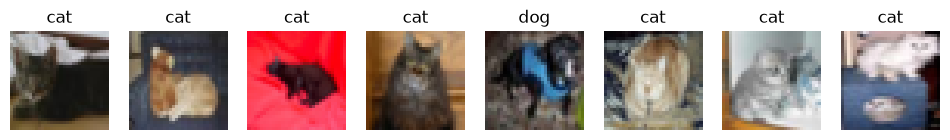

In [3]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, i in zip(axes, range(8)):
    x, y = train_full[i]
    ax.imshow(x.permute(1, 2, 0))          # (C, H, W) → (H, W, C)로 바꿔서 그리기
    ax.set_title("dog" if y == 1 else "cat"); ax.axis("off")
plt.show()

## 2. 학습 / 검증 데이터 나누기
학습 8,000장, 검증 2,000장. 검증 데이터는 학습에 쓰지 않고 성적을 재는 용도예요.

In [4]:
train_data, val_data = random_split(train_full, [8000, 2000])
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
val_loader = DataLoader(val_data, batch_size=256)
test_loader = DataLoader(test_data, batch_size=256)

## 3. 모델 만들기
- **Feature extraction**: [합성곱 → ReLU → Max Pooling] × 2
- **Classification**: Flatten → FC(128) → ReLU → FC(1)

마지막에 시그모이드를 넣지 않는 이유: `BCEWithLogitsLoss`가 시그모이드를 안에 포함하고 있어요.

In [ ]:
class CNN(nn.Module):
    shape_size = 64
    in_features = 128
    
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 32×32×16 → 16×16×16
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # 16×16×32 → 8×8×32

            # nn.Conv2d(32, self.shape_size, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # 8*8*64 → 4*4*64
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),                       # 8×8×32 = 2048
            nn.Linear(32 * 8 * 8, 128), nn.ReLU(),
            
            # nn.Flatten(),                       # 4*4*64 = 1024
            # nn.Linear(self.shape_size * 4 * 4, self.in_features), nn.ReLU(),

            nn.Linear(self.in_features, 1),                  # 출력 1개 (시그모이드 전 값)
        )
    def forward(self, x):
        return self.classifier(self.features(x)).squeeze(1)

model = CNN().to(device)

# 층마다 크기 확인
x = torch.zeros(1, 3, 32, 32).to(device)
for layer in list(model.features) + list(model.classifier):
    x = layer(x)
    print(f"{layer.__class__.__name__:10s} {tuple(x.shape)}")
print("학습할 파라미터 수:", sum(p.numel() for p in model.parameters()))

Conv2d     (1, 16, 32, 32)
ReLU       (1, 16, 32, 32)
MaxPool2d  (1, 16, 16, 16)
Conv2d     (1, 32, 16, 16)
ReLU       (1, 32, 16, 16)
MaxPool2d  (1, 32, 8, 8)
Conv2d     (1, 64, 8, 8)
ReLU       (1, 64, 8, 8)
MaxPool2d  (1, 64, 4, 4)
Flatten    (1, 1024)
Linear     (1, 128)
ReLU       (1, 128)
Linear     (1, 1)
학습할 파라미터 수: 154913


## 4. 손실 함수와 옵티마이저

In [11]:
loss_fn = nn.BCEWithLogitsLoss()                        # 시그모이드 + BCE
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

def predict(out):
    return (torch.sigmoid(out) >= 0.5).float()           # 확률 0.5 이상이면 1(개)

EPOCHS = 10
SAVE_PATH = "./data/best_catdog.pt"

## 5. 학습

In [12]:
def evaluate(loader):
    model.eval()
    total_loss, correct, n = 0, 0, 0
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            out = model(X)
            total_loss += loss_fn(out, y).item() * len(y)
            correct += (predict(out) == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n

history = []
best_val_loss = float("inf")

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss, correct, n = 0, 0, 0
    for X, y in train_loader:
        X, y = X.to(device), y.to(device)

        out = model(X)               # 1. 순전파
        loss = loss_fn(out, y)       # 2. 손실 계산
        optimizer.zero_grad()
        loss.backward()              # 3. 역전파 (커널과 FC층의 기울기 계산)
        optimizer.step()             # 4. 업데이트 (경사하강법 계열: Adam)

        total_loss += loss.item() * len(y)
        correct += (predict(out) == y).sum().item()
        n += len(y)

    val_loss, val_acc = evaluate(val_loader)
    history.append((total_loss / n, correct / n, val_loss, val_acc))
    print(f"epoch {epoch:2d} | train loss {total_loss/n:.4f} acc {correct/n:.3f} | val loss {val_loss:.4f} acc {val_acc:.3f}")

    if val_loss < best_val_loss:     # 검증 loss가 가장 낮을 때의 w 저장
        best_val_loss = val_loss
        torch.save(model.state_dict(), SAVE_PATH)

epoch  1 | train loss 0.3829 acc 0.829 | val loss 0.5111 acc 0.764
epoch  2 | train loss 0.3553 acc 0.844 | val loss 0.5263 acc 0.768
epoch  3 | train loss 0.3324 acc 0.855 | val loss 0.5449 acc 0.755
epoch  4 | train loss 0.3139 acc 0.863 | val loss 0.5425 acc 0.768
epoch  5 | train loss 0.2934 acc 0.875 | val loss 0.5807 acc 0.756
epoch  6 | train loss 0.2686 acc 0.887 | val loss 0.5910 acc 0.747
epoch  7 | train loss 0.2459 acc 0.895 | val loss 0.6266 acc 0.747
epoch  8 | train loss 0.2136 acc 0.916 | val loss 0.6858 acc 0.749
epoch  9 | train loss 0.1958 acc 0.922 | val loss 0.6716 acc 0.753
epoch 10 | train loss 0.1691 acc 0.933 | val loss 0.7429 acc 0.750


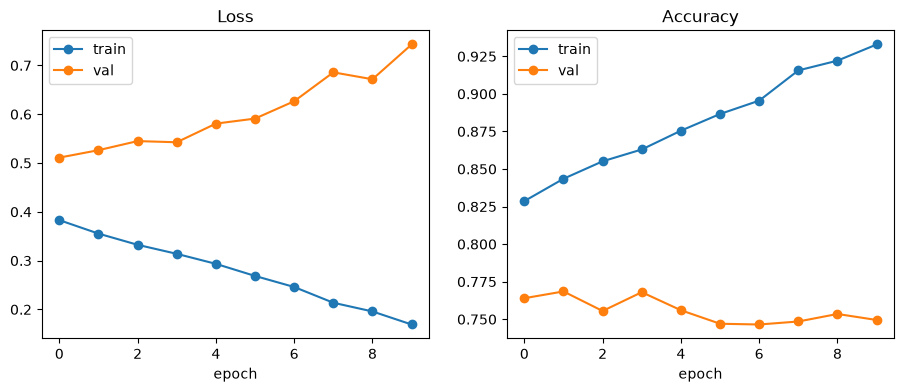

In [13]:
import matplotlib.pyplot as plt
h = list(zip(*history))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(h[0], "o-", label="train"); ax1.plot(h[2], "o-", label="val"); ax1.set_title("Loss"); ax1.set_xlabel("epoch"); ax1.legend()
ax2.plot(h[1], "o-", label="train"); ax2.plot(h[3], "o-", label="val"); ax2.set_title("Accuracy"); ax2.set_xlabel("epoch"); ax2.legend()
plt.show()

## 6. 테스트
검증 loss가 가장 낮았던 w를 불러와서, 학습·검증에 쓰지 않은 테스트 데이터로 평가해요.

test loss 0.5079, test acc 0.763


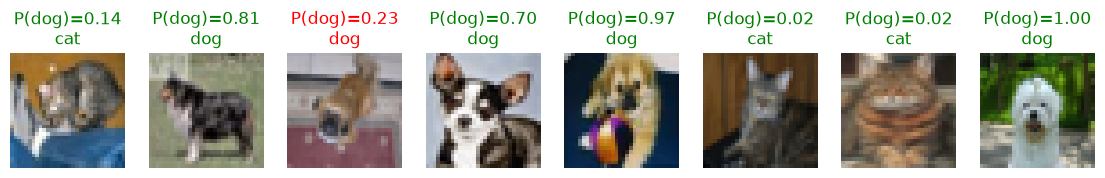

In [14]:
model.load_state_dict(torch.load(SAVE_PATH))
test_loss, test_acc = evaluate(test_loader)
print(f"test loss {test_loss:.4f}, test acc {test_acc:.3f}")

model.eval()
fig, axes = plt.subplots(1, 8, figsize=(14, 2.4))
for ax, i in zip(axes, range(0, 2000, 250)):
    x, y = test_data[i]
    with torch.no_grad():
        p = torch.sigmoid(model(x.unsqueeze(0).to(device))).item()   # 개일 확률
    ax.imshow(x.permute(1, 2, 0)); ax.axis("off")
    ax.set_title(f"P(dog)={p:.2f}\n{'dog' if y == 1 else 'cat'}", color="green" if (p >= 0.5) == (y == 1) else "red")
plt.show()

## 7. 더 해 보기
- `EPOCHS`를 20으로 늘려 보고, 검증 loss가 언제부터 나빠지는지(과적합) 확인해 보세요.
- 합성곱 블록을 하나 더 쌓아 보세요 (`nn.Conv2d(32, 64, 3, padding=1)`). FC층 입력 크기도 같이 바꿔야 해요.
- `nn.BCEWithLogitsLoss` 대신 출력층에 `nn.Sigmoid()`를 넣고 `nn.BCELoss()`를 써도 같은 결과예요.